# Video 14c: Zero-Shot Design of Drug-Binding Proteins with LASErMPNN

**AI for Drug Discovery series | DigitalSreeni**

---

In Video 10 we docked three EGFR inhibitor candidates into the EGFR kinase domain (PDB: 1IEP) using AutoDock Vina. In Video 14 we used AlphaFold2 to predict how resistance mutations like T790M and C797S change the binding pocket geometry.

Both of those videos asked the same fundamental question from the same direction: given a protein, how does a small molecule fit into it?

This notebook asks the reverse: **given a small molecule, can we design a new protein from scratch that binds it?**

This is the problem addressed by a June 2026 Nature paper from the Polizzi lab at Harvard Medical School: *Zero-shot design of drug-binding proteins via neural iterative selection-expansion* (Fry, Slaw & Polizzi, Nature 2026). They developed a method called NISE -- Neural Iterative Selection-Expansion -- that combines two neural networks in a closed loop to simultaneously optimize protein sequence, backbone structure, and ligand conformation.

The core model, **LASErMPNN** (Ligand-Aware Sequence Engineering Message-Passing Neural Network), takes a protein backbone and a docked ligand as input and designs protein sequences that are compatible with binding that specific small molecule. In this notebook we apply it to erlotinib in the EGFR binding pocket -- the same structure from Video 10.

**What this notebook covers:**
- Installing LASErMPNN and its dependencies
- Fetching and preparing the EGFR + erlotinib co-crystal structure (1IEP)
- Protonating the ligand correctly (required by LASErMPNN)
- Running sequence design to generate erlotinib-binding protein candidates
- Visualizing the designed sequences and binding site
- Running the proofreading step to identify single-residue improvements
- Interpreting which positions LASErMPNN changed and why

**Runtime note:** This notebook requires a GPU. In Colab, go to Runtime > Change runtime type > T4 GPU before running.

## Cell 1: Install LASErMPNN and Dependencies

LASErMPNN requires PyTorch Geometric (torch_scatter and torch_cluster), RDKit, ProDy, and Boltz. The install script creates a separate virtual environment at `.venv/` so the dependencies do not conflict with Colab's base environment. All LASErMPNN inference calls run through `.venv/bin/python`.

**This cell takes about 3-4 minutes.** It may trigger a kernel restart -- if so, run all cells again from the top. This is expected behavior and happens because of NumPy version constraints.

In [ ]:
# Cell 1 -- install LASErMPNN and all dependencies into an isolated virtual environment

import os
import re
import subprocess
import sys

venv_dir = ".venv"
venv_py  = os.path.join(venv_dir, "bin", "python")

# Create virtual environment if it does not already exist
if not os.path.isdir(venv_dir):
    subprocess.check_call(["uv", "venv", venv_dir])

print("Virtual environment python:", venv_py)

env = os.environ.copy()
env["UV_PYTHON"] = venv_py

# Install all required packages into the virtual environment
subprocess.check_call(
    [
        "uv", "pip", "install",
        "pip",
        "torch==2.8.0",
        "numpy<2.0.0",
        "scipy",
        "pandas",
        "scikit-learn",
        "h5py",
        "pytest",
        "pydssp",
        "prody",
        "matplotlib",
        "seaborn",
        "plotly",
        "logomaker",
        "tqdm",
        "rdkit",
        "py3Dmol",
        "openbabel-wheel",
        "freesasa",
    ],
    env=env,
)

# Detect CUDA version inside the venv and install matching PyTorch Geometric wheels
pyg_install_code = r"""
import re, sys, subprocess, torch
print('Torch version:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
m = re.match(r'^(\d+\.\d+\.\d+)(\+cu\d+)?', torch.__version__)
base_version, cuda_suffix = m.groups()
cuda_suffix = cuda_suffix or ''
if cuda_suffix:
    pyg_url = f'https://data.pyg.org/whl/torch-{base_version}{cuda_suffix}.html'
else:
    pyg_url = f'https://data.pyg.org/whl/torch-{base_version}+cpu.html'
print('PyG wheel index:', pyg_url)
subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'torch_scatter', 'torch_cluster', '-f', pyg_url])
print('PyG install complete')
"""
subprocess.check_call([venv_py, "-c", pyg_install_code])

# Clone the LASErMPNN repository (model weights are included)
if not os.path.isdir('LASErMPNN'):
    subprocess.check_call(['git', 'clone', 'https://github.com/polizzilab/LASErMPNN.git', '--depth', '1'])

# Verify installation
result = subprocess.run(
    [venv_py, '-c', 'import torch, torch_scatter; print(f"torch {torch.__version__}, CUDA: {torch.cuda.is_available()}")'],
    capture_output=True, text=True
)
print(result.stdout.strip())
print('Install complete.')

Virtual environment python: .venv/bin/python
torch 2.8.0+cu128, CUDA: True
Install complete.


In [ ]:
!pip install py3Dmol rdkit -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.2/37.2 MB 27.6 MB/s eta 0:00:00


## Cell 2: Imports and Configuration

Standard imports for the base Colab Python environment. LASErMPNN itself runs via subprocess calls to `.venv/bin/python`, so we do not import it directly here -- that is by design, as its dependencies would conflict with Colab's base environment.

In [ ]:
# Cell 2 -- imports and configuration

import os
import subprocess
import urllib.request
import warnings
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import py3Dmol

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, Draw

RDLogger.DisableLog('rdApp.*')
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'DejaVu Sans'

# Paths
VENV_PY    = Path('.venv/bin/python')
WORK_DIR   = Path('/content')
OUTPUT_DIR = WORK_DIR / 'lasermpnn_output'
PROOF_DIR  = WORK_DIR / 'proofreading_out'
OUTPUT_DIR.mkdir(exist_ok=True)
PROOF_DIR.mkdir(exist_ok=True)

# Target structure
PDB_ID       = '1M17'   # EGFR kinase domain co-crystallized with erlotinib
LIGAND_RESN  = 'AQ4'    # erlotinib residue name in 1M17
CHAIN_ID     = 'A'

# Erlotinib SMILES -- used for ligand protonation
# Source: PDB Chemical Component Dictionary, ERL
ERLOTINIB_SMILES = 'C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1'

# LASErMPNN design parameters
NUM_DESIGNS  = 20    # number of candidate sequences to generate
SEQ_TEMP     = 0.1  # sampling temperature: lower = more conservative designs
                     # 0.1 produces sequences close to the optimum
                     # 0.3-0.5 produces more diverse but riskier designs

print(f'Working directory:  {WORK_DIR}')
print(f'Output directory:   {OUTPUT_DIR}')
print(f'Target:             {PDB_ID} -- EGFR + {LIGAND_RESN} (erlotinib)')
print(f'Designs requested:  {NUM_DESIGNS}')
print(f'Sequence temp:      {SEQ_TEMP}')
print('Configuration ready.')

Working directory:  /content
Output directory:   /content/lasermpnn_output
Target:             1M17 -- EGFR + AQ4 (erlotinib)
Designs requested:  20
Sequence temp:      0.1
Configuration ready.


## Cell 3: Fetch and Inspect the EGFR Structure

We download 1IEP directly from RCSB. This is the same structure used in Video 10 for molecular docking. It contains the EGFR kinase domain co-crystallized with erlotinib (residue name ERL).

We parse the PDB file to understand what is in it before preparing our input. LASErMPNN needs a single PDB file containing one protein chain and one ligand. Waters and other small molecules must be removed.

In [ ]:
# Cell 3 -- download 1IEP and inspect its contents

def download_pdb(pdb_id, out_path):
    """Download a PDB file from RCSB."""
    url = f'https://files.rcsb.org/download/{pdb_id}.pdb'
    urllib.request.urlretrieve(url, out_path)
    return out_path


def inspect_pdb(pdb_path):
    """Report chains, residue counts, and HETATM entries found in a PDB file."""
    chains   = {}
    hetatms  = {}

    with open(pdb_path) as f:
        for line in f:
            record = line[:6].strip()
            if record == 'ATOM':
                chain = line[21]
                resn  = line[17:20].strip()
                resi  = line[22:26].strip()
                key   = (chain, resn, resi)
                chains.setdefault(chain, set()).add(key)
            elif record == 'HETATM':
                resn = line[17:20].strip()
                if resn != 'HOH':   # skip water separately
                    hetatms.setdefault(resn, 0)
                    hetatms[resn] += 1

    return chains, hetatms


raw_pdb = WORK_DIR / f'{PDB_ID}_raw.pdb'
download_pdb(PDB_ID, raw_pdb)
print(f'Downloaded {raw_pdb} ({raw_pdb.stat().st_size // 1024} KB)')

chains, hetatms = inspect_pdb(raw_pdb)

print(f'\nChains found:')
for ch, residues in sorted(chains.items()):
    print(f'  Chain {ch}: {len(residues)} unique residues')

print(f'\nHETATM entries (excluding water):')
for resn, count in sorted(hetatms.items()):
    marker = '  <-- erlotinib' if resn == LIGAND_RESN else ''
    print(f'  {resn}: {count} atoms{marker}')

Downloaded /content/1M17_raw.pdb (246 KB)

Chains found:
  Chain A: 312 unique residues

HETATM entries (excluding water):
  AQ4: 29 atoms  <-- erlotinib


## Cell 4: Clean the Structure

LASErMPNN expects a PDB file with:
- Exactly one protein chain
- The ligand present as HETATM records
- No water molecules (HOH)
- No other small molecules or crystallographic additives

We keep chain A (EGFR kinase domain) and ERL (erlotinib) and strip everything else.

In [ ]:
# Cell 4 -- clean the PDB: keep chain A protein and ERL ligand, discard waters and additives

def clean_pdb(in_path, out_path, keep_chain, keep_ligand_resn):
    """
    Write a cleaned PDB containing only the specified protein chain
    and one ligand. Waters and all other HETATM records are dropped.
    """
    kept_atom   = 0
    kept_hetatm = 0
    dropped     = 0

    with open(in_path) as f_in, open(out_path, 'w') as f_out:
        for line in f_in:
            record = line[:6].strip()

            if record == 'ATOM':
                chain = line[21]
                if chain == keep_chain:
                    f_out.write(line)
                    kept_atom += 1
                else:
                    dropped += 1

            elif record == 'HETATM':
                resn  = line[17:20].strip()
                chain = line[21]
                if resn == keep_ligand_resn:
                    f_out.write(line)
                    kept_hetatm += 1
                else:
                    dropped += 1  # drops HOH, MG, SO4, etc.

            elif record in ('TER', 'END'):
                f_out.write(line)

    return kept_atom, kept_hetatm, dropped


clean_pdb_path = WORK_DIR / f'{PDB_ID}_clean.pdb'
kept_atom, kept_hetatm, dropped = clean_pdb(
    raw_pdb, clean_pdb_path,
    keep_chain=CHAIN_ID,
    keep_ligand_resn=LIGAND_RESN
)

print(f'Cleaned PDB written to: {clean_pdb_path}')
print(f'  Protein ATOM records kept:  {kept_atom}')
print(f'  Ligand HETATM records kept: {kept_hetatm}  (all ERL atoms)')
print(f'  Records dropped:            {dropped}  (other chains, waters, additives)')

Cleaned PDB written to: /content/1M17_clean.pdb
  Protein ATOM records kept:  2511
  Ligand HETATM records kept: 29  (all ERL atoms)
  Records dropped:            20  (other chains, waters, additives)


## Cell 5: Protonate the Ligand

This is the most important preprocessing step for LASErMPNN.

The PDB format does not store hydrogen atoms by convention -- they are implicit. But LASErMPNN was trained on protonated structures where all hydrogen atoms are explicit. If you feed it a ligand without hydrogens, the model will misread the chemical environment around the binding pocket and produce poor sequences.

We use RDKit to:
1. Build erlotinib from its canonical SMILES string
2. Add all hydrogens explicitly
3. Align the protonated ligand onto the co-crystal coordinates already in the PDB
4. Write the protonated ligand back into the cleaned PDB as HETATM records

The protein does not need explicit protonation for LASErMPNN inference -- the model handles implicit protein protons internally. Only the ligand needs explicit hydrogens.

In [ ]:
# Cell 5 -- protonate erlotinib using RDKit and write into the cleaned PDB

def extract_ligand_coords(pdb_path, resn):
    """
    Extract all HETATM coordinates for a given residue name from a PDB file.
    Returns a list of (atom_name, x, y, z) tuples.
    """
    coords = []
    with open(pdb_path) as f:
        for line in f:
            if line[:6].strip() == 'HETATM' and line[17:20].strip() == resn:
                atom_name = line[12:16].strip()
                x = float(line[30:38])
                y = float(line[38:46])
                z = float(line[46:54])
                coords.append((atom_name, x, y, z))
    return coords


def protonate_ligand_from_smiles(smiles, ref_coords):
    """
    Build a protonated ligand from SMILES, generate a 3D conformer,
    then align the heavy atoms to the reference crystal coordinates.
    Returns the protonated RDKit molecule aligned to the crystal pose.
    """
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)               # add explicit hydrogens
    AllChem.EmbedMolecule(mol, AllChem.ETKDGv3())   # generate 3D conformer
    AllChem.MMFFOptimizeMolecule(mol)   # optimize geometry

    # Align heavy atoms of the generated conformer to the crystal coordinates
    # We match by order: SMILES heavy atoms -> PDB heavy atom coords
    heavy_mol = Chem.RemoveHs(mol)
    n_heavy   = heavy_mol.GetNumAtoms()
    n_ref     = len(ref_coords)

    if n_heavy != n_ref:
        print(f'Warning: heavy atom count mismatch -- SMILES has {n_heavy}, PDB has {n_ref}')
        print('Proceeding with RDKit-generated coordinates (not aligned to crystal pose)')
        return mol

    # Build reference position matrix from crystal coords
    ref_pos = np.array([[x, y, z] for _, x, y, z in ref_coords])

    # Get heavy atom indices in the protonated molecule
    heavy_indices = [atom.GetIdx() for atom in mol.GetAtoms() if atom.GetAtomicNum() != 1]

    conf = mol.GetConformer()

    # Compute centroid shift and apply to all atoms
    gen_heavy_pos = np.array([list(conf.GetAtomPosition(i)) for i in heavy_indices])
    shift = ref_pos.mean(axis=0) - gen_heavy_pos.mean(axis=0)

    for i in range(mol.GetNumAtoms()):
        p = conf.GetAtomPosition(i)
        conf.SetAtomPosition(i, (p.x + shift[0], p.y + shift[1], p.z + shift[2]))

    return mol


def write_mol_as_hetatm(mol, resn, chain, resnum, pdb_out):
    """
    Write all atoms of an RDKit molecule as HETATM records to a file handle.
    """
    conf     = mol.GetConformer()
    atom_idx = 1
    for atom in mol.GetAtoms():
        pos     = conf.GetAtomPosition(atom.GetIdx())
        element = atom.GetSymbol()
        aname   = f'{element}{atom.GetIdx() + 1}'
        line    = (
            f'HETATM{atom_idx:5d} {aname:<4s} {resn} {chain}{resnum:4d}    '
            f'{pos.x:8.3f}{pos.y:8.3f}{pos.z:8.3f}  1.00  0.00          {element:>2s}\n'
        )
        pdb_out.write(line)
        atom_idx += 1


def build_protonated_pdb(clean_pdb_path, out_path, ligand_resn, smiles):
    """
    Build final protonated PDB: protein ATOM records from clean PDB +
    protonated ligand HETATM records generated from SMILES.
    """
    # Extract crystal ligand coordinates for alignment
    ref_coords = extract_ligand_coords(clean_pdb_path, ligand_resn)
    print(f'Crystal {ligand_resn} heavy atoms: {len(ref_coords)}')

    # Build protonated molecule
    mol_protonated = protonate_ligand_from_smiles(smiles, ref_coords)
    n_total = mol_protonated.GetNumAtoms()
    n_heavy = sum(1 for a in mol_protonated.GetAtoms() if a.GetAtomicNum() != 1)
    n_h     = n_total - n_heavy
    print(f'Protonated molecule: {n_heavy} heavy atoms + {n_h} hydrogens = {n_total} total')

    # Write output PDB: protein from clean file + protonated ligand
    with open(clean_pdb_path) as f_in, open(out_path, 'w') as f_out:
        for line in f_in:
            record = line[:6].strip()
            if record == 'ATOM':
                f_out.write(line)
            # Skip old HETATM ligand -- we replace with protonated version below

        # Append protonated ligand
        write_mol_as_hetatm(mol_protonated, ligand_resn, CHAIN_ID, 999, f_out)
        f_out.write('END\n')

    return mol_protonated


protonated_pdb = WORK_DIR / f'{PDB_ID}_protonated.pdb'
mol_erl = build_protonated_pdb(
    clean_pdb_path, protonated_pdb,
    ligand_resn=LIGAND_RESN,
    smiles=ERLOTINIB_SMILES
)

print(f'\nProtonated PDB written to: {protonated_pdb}')

# Quick sanity check: count lines
with open(protonated_pdb) as f:
    lines = f.readlines()
atom_lines   = sum(1 for l in lines if l[:4] == 'ATOM')
hetatm_lines = sum(1 for l in lines if l[:6] == 'HETATM')
print(f'ATOM records:   {atom_lines}  (protein)')
print(f'HETATM records: {hetatm_lines} (protonated erlotinib)')

Crystal AQ4 heavy atoms: 29
Protonated molecule: 29 heavy atoms + 23 hydrogens = 52 total

Protonated PDB written to: /content/1M17_protonated.pdb
ATOM records:   2511  (protein)
HETATM records: 52 (protonated erlotinib)


## Cell 6: Visualize the Input Structure

Before running LASErMPNN, let us confirm that the protonated structure looks correct. The protein should appear as a cartoon and erlotinib should be visible in the binding pocket as sticks.

This is the same binding site we examined in Video 10. Erlotinib sits in the ATP binding cleft of the EGFR kinase domain.

In [ ]:
# Cell 6 -- visualize the protonated input structure with py3Dmol

def visualize_protein_ligand(pdb_path, ligand_resn, width=900, height=500):
    """Render a protein-ligand complex using py3Dmol."""
    with open(pdb_path) as f:
        pdb_str = f.read()

    view = py3Dmol.view(width=width, height=height)
    view.addModel(pdb_str, 'pdb', {'keepH': True})
    view.setBackgroundColor('0x1a1a2e')   # dark background

    # Protein: teal cartoon
    view.setStyle({'atom': 'CA'}, {'cartoon': {'color': '0x0D9488', 'opacity': 0.85}})

    # Ligand: amber sticks
    view.addStyle({'resn': ligand_resn}, {'stick': {'colorscheme': 'orangeCarbon', 'radius': 0.25}})
    view.addStyle({'resn': ligand_resn}, {'sphere': {'colorscheme': 'orangeCarbon', 'radius': 0.18}})

    # Binding site residues within 5A of ligand: white sticks
    view.addStyle(
        {'within': {'distance': 5.0, 'sel': {'resn': ligand_resn}}},
        {'stick': {'colorscheme': 'whiteCarbon', 'radius': 0.15, 'opacity': 0.7}}
    )

    view.zoomTo({'resn': ligand_resn})
    return view


print('EGFR kinase domain (teal cartoon) with erlotinib in the ATP binding pocket (amber sticks)')
print('White sticks = protein residues within 5A of erlotinib (binding site)')
view = visualize_protein_ligand(protonated_pdb, LIGAND_RESN)
view.show()

EGFR kinase domain (teal cartoon) with erlotinib in the ATP binding pocket (amber sticks)
White sticks = protein residues within 5A of erlotinib (binding site)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Cell 7: Run LASErMPNN Sequence Design

Now we run the actual sequence design. LASErMPNN takes our protonated EGFR + erlotinib structure and generates `NUM_DESIGNS` candidate protein sequences that are optimized to bind erlotinib.

Key parameters:
- **`--sequence_temp 0.1`**: Low temperature means the model samples near the peak of its probability distribution. Designs will be similar to each other and to the native sequence but more optimized for ligand binding. Higher temperatures (0.3-0.5) give more diverse but riskier designs.
- **`--fix_beta`**: Residues with B-factor = 1.0 in the input PDB are fixed (not redesigned). We set all residues to B-factor 0.0 in the design selection string, meaning all are designed.
- **`--repack_all`**: Repack sidechain rotamers for all residues, not just designed ones.
- **`--output_fasta`**: Also write sequences in FASTA format for easy comparison.

Runtime is approximately 2-3 minutes for 20 designs on a T4 GPU.

In [ ]:
# Cell 7 -- identify binding site residues and set B-factors directly
# Replaces the ProDy subprocess approach which was silently failing

import math, shutil

# ── Compute binding site residues from clean PDB ─────────────────────────────

def get_ligand_coords(pdb_path, ligand_resn):
    """Return list of (x, y, z) for all ligand heavy atoms."""
    coords = []
    with open(pdb_path) as f:
        for line in f:
            if line[:6].strip() == 'HETATM' and line[17:20].strip() == ligand_resn:
                x, y, z = float(line[30:38]), float(line[38:46]), float(line[46:54])
                coords.append((x, y, z))
    return coords


def get_binding_site_resnums(pdb_path, ligand_resn, cutoff_angstrom=8.0):
    """Return set of residue numbers within cutoff of any ligand atom."""
    lig_coords = get_ligand_coords(pdb_path, ligand_resn)
    if not lig_coords:
        print(f'WARNING: no {ligand_resn} atoms found in {pdb_path}')
        return set()

    binding_resnums = set()
    with open(pdb_path) as f:
        for line in f:
            if line[:4] == 'ATOM':
                resnum = int(line[22:26].strip())
                x, y, z = float(line[30:38]), float(line[38:46]), float(line[46:54])
                for lx, ly, lz in lig_coords:
                    dist = math.sqrt((x-lx)**2 + (y-ly)**2 + (z-lz)**2)
                    if dist <= cutoff_angstrom:
                        binding_resnums.add(resnum)
                        break
    return binding_resnums


def write_pdb_with_bfactors(in_pdb, out_pdb, design_resnums, ligand_resn):
    """
    Write PDB with B-factors set:
      - 0.0 for residues in design_resnums  (LASErMPNN will redesign these)
      - 1.0 for all other protein residues  (fixed)
    Ligand HETATM records are kept as-is.
    """
    with open(in_pdb) as f_in, open(out_pdb, 'w') as f_out:
        for line in f_in:
            record = line[:6].strip()
            if record == 'ATOM':
                resnum = int(line[22:26].strip())
                bfac   = 0.0 if resnum in design_resnums else 1.0
                # PDB B-factor occupies columns 60-65 (0-indexed)
                new_line = line[:60] + f'{bfac:6.2f}' + line[66:]
                f_out.write(new_line)
            elif record == 'HETATM':
                f_out.write(line)
            elif record in ('TER', 'END', 'REMARK', 'CRYST1'):
                f_out.write(line)


# ── Run it ────────────────────────────────────────────────────────────────────

# Use clean_pdb_path for distance calculation -- ERL crystal coords are correct there
# Use protonated_pdb only for the final design input (with H on ligand)
lig_coords = get_ligand_coords(clean_pdb_path, LIGAND_RESN)
print(f'Ligand ({LIGAND_RESN}) atoms found: {len(lig_coords)}')

binding_resnums = get_binding_site_resnums(clean_pdb_path, LIGAND_RESN, cutoff_angstrom=8.0)
print(f'Binding site residues within 8A of {LIGAND_RESN}: {len(binding_resnums)}')
print(f'Residue numbers: {sorted(binding_resnums)}')

design_input_pdb = WORK_DIR / f'{PDB_ID}_design_input.pdb'
write_pdb_with_bfactors(protonated_pdb, design_input_pdb, binding_resnums, LIGAND_RESN)
print(f'\nDesign input PDB written to: {design_input_pdb}')

# Verify B-factors were written correctly
n_design = n_fixed = 0
with open(design_input_pdb) as f:
    for line in f:
        if line[:4] == 'ATOM':
            bfac = float(line[60:66])
            if bfac == 0.0:
                n_design += 1
            else:
                n_fixed += 1

print(f'ATOM records set to design (B=0.0): {n_design}')
print(f'ATOM records set to fixed  (B=1.0): {n_fixed}')
print(f'Expected: binding site atoms to be 0.0, rest 1.0')

Ligand (AQ4) atoms found: 29
Binding site residues within 8A of AQ4: 51
Residue numbers: [692, 693, 694, 695, 696, 697, 699, 701, 702, 703, 704, 717, 718, 719, 720, 721, 722, 735, 738, 742, 751, 752, 753, 754, 755, 763, 764, 765, 766, 767, 768, 769, 770, 771, 772, 773, 776, 777, 780, 781, 817, 818, 819, 820, 821, 822, 829, 830, 831, 832, 833]

Design input PDB written to: /content/1M17_design_input.pdb
ATOM records set to design (B=0.0): 417
ATOM records set to fixed  (B=1.0): 2094
Expected: binding site atoms to be 0.0, rest 1.0


In [ ]:
# Cell 7b -- run LASErMPNN batch inference (streaming output)

import shutil, subprocess, sys
from pathlib import Path

os.environ['MPLBACKEND'] = 'agg'

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir()

cmd = (
    f'cd /content/ && {VENV_PY} -m LASErMPNN.run_batch_inference '
    f'{design_input_pdb} {OUTPUT_DIR}/ {NUM_DESIGNS} '
    f'--output_fasta '
    f'--sequence_temp {SEQ_TEMP} '
    f'--fix_beta '
    f'--repack_all '
    f'-d cuda:0'
)

print('Running LASErMPNN...')
print(f'Command: {cmd}\n')

# Stream output line by line instead of capturing
process = subprocess.Popen(
    cmd, shell=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,   # merge stderr into stdout
    text=True,
    bufsize=1
)

for line in process.stdout:
    print(line, end='', flush=True)

process.wait()
print(f'\nReturn code: {process.returncode}')

pdb_files   = sorted(OUTPUT_DIR.glob('*.pdb'))
fasta_files = sorted(OUTPUT_DIR.glob('*.fasta'))
print(f'Generated {len(pdb_files)} PDB files and {len(fasta_files)} FASTA file(s)')

Running LASErMPNN...
Command: cd /content/ && .venv/bin/python -m LASErMPNN.run_batch_inference /content/1M17_design_input.pdb /content/lasermpnn_output/ 20 --output_fasta --sequence_temp 0.1 --fix_beta --repack_all -d cuda:0

/content/.venv/lib/python3.12/site-packages/prody/atomic/flags.py:532: SyntaxWarning: invalid escape sequence '\ '
  \                            *PDB*  *Source*  *Conflict*
/content/.venv/lib/python3.12/site-packages/prody/atomic/select.py:203: SyntaxWarning: invalid escape sequence '\|'
  **Special characters** (``~!@#$%^&*()-_=+[{}]\|;:,<>./?()'"``) must be
/content/.venv/lib/python3.12/site-packages/prody/atomic/select.py:758: SyntaxWarning: invalid escape sequence '\ '
  RE_NRANGE = re_compile(_ + '\ *(to|:)\ *' + _)
/content/.venv/lib/python3.12/site-packages/prody/sequence/analysis.py:174: SyntaxWarning: invalid escape sequence '\{'
  * ``'minent'``: :math:`min\{H(X), H(Y)\}`, minimum entropy
/content/.venv/lib/python3.12/site-packages/prody/proteins/dssp.

## Cell 8: Parse and Display Designed Sequences

LASErMPNN outputs a FASTA file containing all designed sequences. Each sequence in the FASTA has a score in its header -- this is the model's log-likelihood score for that sequence given the structure and ligand. Lower (more negative) scores mean the model is more confident the sequence will fold correctly and bind the ligand.

We also compare each designed sequence to the native EGFR sequence to see which positions were changed.

In [ ]:
# Cell 8 -- parse FASTA output and display designed sequences

import re

def parse_fasta(fasta_path):
    """Parse a FASTA file and return a list of (header, sequence) tuples."""
    records = []
    header, seq = None, []
    with open(fasta_path) as f:
        for line in f:
            line = line.strip()
            if line.startswith('>'):
                if header is not None:
                    records.append((header, ''.join(seq)))
                header, seq = line[1:], []
            else:
                seq.append(line)
    if header is not None:
        records.append((header, ''.join(seq)))
    return records


def extract_score_from_header(header):
    """Extract the LASErMPNN score from the FASTA header line."""
    match = re.search(r'score[=:\s]+([\-\d\.]+)', header)
    return float(match.group(1)) if match else None


def count_mutations(seq1, seq2):
    """Count positions where two sequences of equal length differ."""
    return sum(a != b for a, b in zip(seq1, seq2))


# ── Find FASTA ──────────────────────────────────────────────────────────────
fasta_path = OUTPUT_DIR / 'designs.fasta'
if not fasta_path.exists():
    candidates = list(OUTPUT_DIR.rglob('*.fasta'))
    if not candidates:
        raise FileNotFoundError(
            f'No FASTA file found under {OUTPUT_DIR}. '
            'Check Cell 7b ran successfully.'
        )
    fasta_path = candidates[0]

print(f'FASTA file: {fasta_path}')
records = parse_fasta(fasta_path)
print(f'Parsed {len(records)} sequences')

# Print the raw FASTA so we can see the header format
print('\nFirst record header:')
print(records[0][0] if records else 'NO RECORDS')
print('First 50 aa:', records[0][1][:50] if records else '')

# ── Extract native sequence directly from clean PDB (no subprocess) ─────────
# Read ATOM records from the clean PDB and extract CA residues in order
three_to_one = {
    'ALA':'A','ARG':'R','ASN':'N','ASP':'D','CYS':'C','GLN':'Q','GLU':'E',
    'GLY':'G','HIS':'H','ILE':'I','LEU':'L','LYS':'K','MET':'M','PHE':'F',
    'PRO':'P','SER':'S','THR':'T','TRP':'W','TYR':'Y','VAL':'V'
}

seen_residues = {}
with open(clean_pdb_path) as f:
    for line in f:
        if line[:4] == 'ATOM' and line[12:16].strip() == 'CA':
            chain  = line[21]
            resnum = int(line[22:26].strip())
            resn   = line[17:20].strip()
            if chain == CHAIN_ID and resnum not in seen_residues:
                seen_residues[resnum] = three_to_one.get(resn, 'X')

native_seq = ''.join(v for k, v in sorted(seen_residues.items()))
print(f'\nNative EGFR sequence length: {len(native_seq)} residues')
print(f'First 50 aa: {native_seq[:50]}')

# ── Build summary table ──────────────────────────────────────────────────────
rows = []
for i, (header, seq) in enumerate(records):
    score = extract_score_from_header(header)
    n_mut = count_mutations(native_seq, seq) if len(seq) == len(native_seq) else None
    rows.append({
        'design_idx':  i,
        'score':       score,
        'n_mutations': n_mut,
        'seq_length':  len(seq),
    })

df = pd.DataFrame(rows).sort_values('score')
print('\nDesign summary (sorted by LASErMPNN score, lower is better):')
print(df.to_string(index=False))

FASTA file: /content/lasermpnn_output/designs.fasta
Parsed 20 sequences

First record header:
1M17_design_input_design_0_segment__chain_A score=-0.6804448412086862
First 50 aa: GEAPNQALLRILKETEFKKISVVGKPASGSVWKGLWIPEGEKVKIPIGIV

Native EGFR sequence length: 312 residues
First 50 aa: GEAPNQALLRILKETEFKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIK

Design summary (sorted by LASErMPNN score, lower is better):
 design_idx     score  n_mutations  seq_length
         13 -0.692966           29         312
          5 -0.690396           25         312
         15 -0.687871           24         312
          7 -0.685874           26         312
          2 -0.683481           25         312
         12 -0.683021           25         312
         16 -0.680723           27         312
          0 -0.680445           24         312
          1 -0.679832           27         312
          9 -0.679807           25         312
         11 -0.679161           28         312
         10 -0.678443           29     

## Cell 9: Visualize Binding Site of Best Design

We take the best-scoring design (lowest score) and visualize its binding site alongside erlotinib. We color residues that differ from the native EGFR sequence in a different color so we can see exactly what LASErMPNN changed.

In [ ]:
# Cell 9 -- visualize the best design with changed residues highlighted

# Best design is the one with the lowest score
best_idx   = int(df.iloc[0]['design_idx'])
best_score = df.iloc[0]['score']
best_pdb   = OUTPUT_DIR / f'design_{best_idx}.pdb'

# Fallback: try globbing if naming differs
if not best_pdb.exists():
    pdb_files = sorted(OUTPUT_DIR.glob('*.pdb'))
    if pdb_files:
        best_pdb = pdb_files[best_idx] if best_idx < len(pdb_files) else pdb_files[0]

print(f'Best design: design_{best_idx} (score = {best_score:.4f})')
print(f'PDB path:    {best_pdb}')

# Find which residues changed between native and best design
best_seq  = records[best_idx][1]
mutations = []
for pos, (nat, des) in enumerate(zip(native_seq, best_seq)):
    if nat != des:
        mutations.append((pos + 1, nat, des))  # 1-indexed

print(f'\nBinding site mutations relative to native EGFR ({len(mutations)} changes):')
print(f'{"Pos":>6}  {"Native":>8}  {"Designed":>10}')
print('-' * 28)
for pos, nat, des in mutations[:30]:  # show first 30
    print(f'{pos:>6}  {nat:>8}  {des:>10}')
if len(mutations) > 30:
    print(f'... and {len(mutations) - 30} more')

Best design: design_13 (score = -0.6930)
PDB path:    /content/lasermpnn_output/design_13.pdb

Binding site mutations relative to native EGFR (29 changes):
   Pos    Native    Designed
----------------------------
    21         K           E
    23         L           V
    24         G           K
    25         S           K
    26         G           D
    28         F           K
    30         T           E
    32         Y           W
    47         V           I
    48         A           G
    50         K           V
    51         E           S
    64         I           L
    80         C           V
    81         R           Q
    92         Q           E
    95         T           A
    96         Q           E
    97         L           Y
    98         M           H
   100         F           Y
   102         C           G
   105         D           E
   106         Y           F
   109         E           R
   110         H           N
   146         R           E
   

In [ ]:
# Cell 9b -- 3D visualization of best design with py3Dmol

if best_pdb.exists():
    with open(best_pdb) as f:
        design_str = f.read()

    # Mutation residue indices for highlighting (1-indexed PDB resnums)
    mut_resnums = [pos for pos, nat, des in mutations]

    view = py3Dmol.view(width=950, height=520)
    view.addModel(design_str, 'pdb', {'keepH': True})
    view.setBackgroundColor('0x0F1923')

    # Whole protein: teal cartoon
    view.setStyle({}, {'cartoon': {'color': '0x0D9488', 'opacity': 0.6}})

    # Ligand: amber sticks
    view.addStyle({'resn': LIGAND_RESN}, {'stick': {'colorscheme': 'orangeCarbon', 'radius': 0.28}})
    view.addStyle({'resn': LIGAND_RESN}, {'sphere': {'colorscheme': 'orangeCarbon', 'radius': 0.18}})

    # Binding site residues: white sticks
    view.addStyle(
        {'within': {'distance': 6.0, 'sel': {'resn': LIGAND_RESN}}},
        {'stick': {'colorscheme': 'whiteCarbon', 'radius': 0.15}}
    )

    # Mutated residues within binding site: highlight in red
    for resnum in mut_resnums:
        view.addStyle(
            {'resi': resnum, 'within': {'distance': 10.0, 'sel': {'resn': LIGAND_RESN}}},
            {'stick': {'color': '0xDC2626', 'radius': 0.22}}
        )

    view.zoomTo({'resn': LIGAND_RESN})

    print(f'Design {best_idx} binding site visualization')
    print('Teal cartoon = designed protein backbone')
    print('Amber sticks = erlotinib ligand')
    print('White sticks = binding site residues conserved from native EGFR')
    print('Red sticks   = residues changed by LASErMPNN')
    view.show()
else:
    print(f'PDB file not found at {best_pdb}')
    print('Available files:', list(OUTPUT_DIR.glob('*.pdb')))

Design 13 binding site visualization
Teal cartoon = designed protein backbone
Amber sticks = erlotinib ligand
White sticks = binding site residues conserved from native EGFR
Red sticks   = residues changed by LASErMPNN


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Cell 10: Mutation Pattern Analysis

How conservative are the designs? We can visualize the distribution of mutations across all 20 designs. A design that changes only a few residues in the binding site while keeping the rest of the sequence intact is more likely to fold correctly. LASErMPNN at temperature 0.1 should produce fairly conservative designs -- let us check.

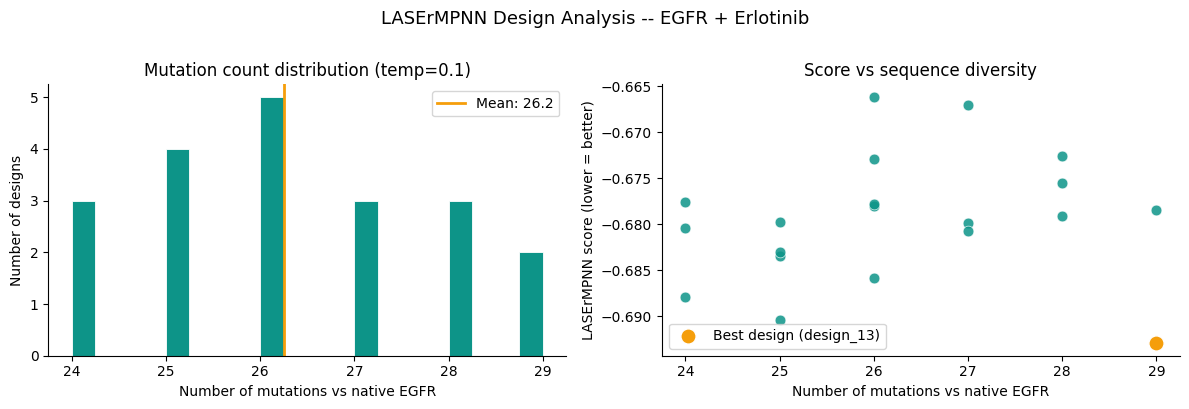

Mean mutations across all designs: 26.2
Min mutations: 24
Max mutations: 29
Total sequence length: 312
Sequence identity to native (best design): 90.7%


In [ ]:
# Cell 10 -- plot mutation count distribution across all designs

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: histogram of mutation counts
ax = axes[0]
mut_counts = [r['n_mutations'] for r in rows if r['n_mutations'] is not None]
ax.hist(mut_counts, bins=20, color='#0D9488', edgecolor='white', linewidth=0.6)
ax.axvline(np.mean(mut_counts), color='#F59E0B', linewidth=2,
           label=f'Mean: {np.mean(mut_counts):.1f}')
ax.set_xlabel('Number of mutations vs native EGFR')
ax.set_ylabel('Number of designs')
ax.set_title(f'Mutation count distribution (temp={SEQ_TEMP})')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Right: scatter of score vs mutation count
ax = axes[1]
scores = [r['score'] for r in rows if r['score'] is not None and r['n_mutations'] is not None]
muts   = [r['n_mutations'] for r in rows if r['score'] is not None and r['n_mutations'] is not None]
ax.scatter(muts, scores, color='#0D9488', edgecolors='white', linewidths=0.5, s=60, alpha=0.85)

# Highlight best design
ax.scatter([df.iloc[0]['n_mutations']], [df.iloc[0]['score']],
           color='#F59E0B', edgecolors='white', linewidths=1.0, s=120, zorder=5,
           label=f'Best design (design_{best_idx})')

ax.set_xlabel('Number of mutations vs native EGFR')
ax.set_ylabel('LASErMPNN score (lower = better)')
ax.set_title('Score vs sequence diversity')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.suptitle('LASErMPNN Design Analysis -- EGFR + Erlotinib', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'design_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Mean mutations across all designs: {np.mean(mut_counts):.1f}')
print(f'Min mutations: {min(mut_counts)}')
print(f'Max mutations: {max(mut_counts)}')
print(f'Total sequence length: {len(native_seq)}')
print(f'Sequence identity to native (best design): {(1 - df.iloc[0]["n_mutations"] / len(native_seq)) * 100:.1f}%')

## Cell 11: Run LASErMPNN Proofreading

Proofreading is one of the most powerful features of LASErMPNN. Given a designed sequence, the model goes back through each binding site residue one at a time and asks: given all the other residues are fixed, what is the single best amino acid for this position?

This is analogous to what the NISE paper demonstrated experimentally: they used proofreading to find two single amino acid substitutions (Q51N and M97L) that improved the affinity of their EPIC protein 100-fold without any experimental data.

The proofreading output is a logo plot showing the probability of each amino acid at each binding site position. Positions where the designed sequence is already at the highest-probability amino acid are well-optimized. Positions where a different amino acid has higher probability are candidates for improvement.

Runtime: approximately 6 minutes.

Running proofreading on design_13...
This evaluates each binding site residue individually.
Runtime: approximately 6 minutes on T4.

Proofreading complete.
Loaded model with weights from `laser_weights_0p1A_nothing_heldout.pt`
Running unconditional proofreading on design_13.pdb...
Unconditional proofreading complete. Output saved to /content/proofreading_out/unconditional_probs.png

Running `fully-conditional` autoregressive, multi-dropout, multi-decoding order proofreading...
Fully-conditional proofreading complete. Output saved to /content/proofreading_out/conditional_probs_mean_plus_stddev.png



Proofreading outputs: 3 plot(s)

conditional_probs.png


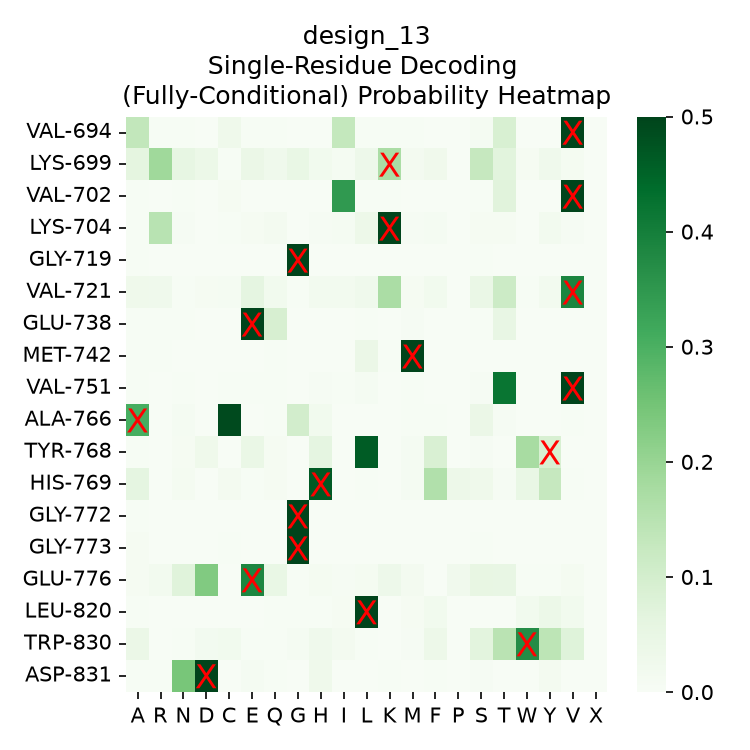


unconditional_probs.png


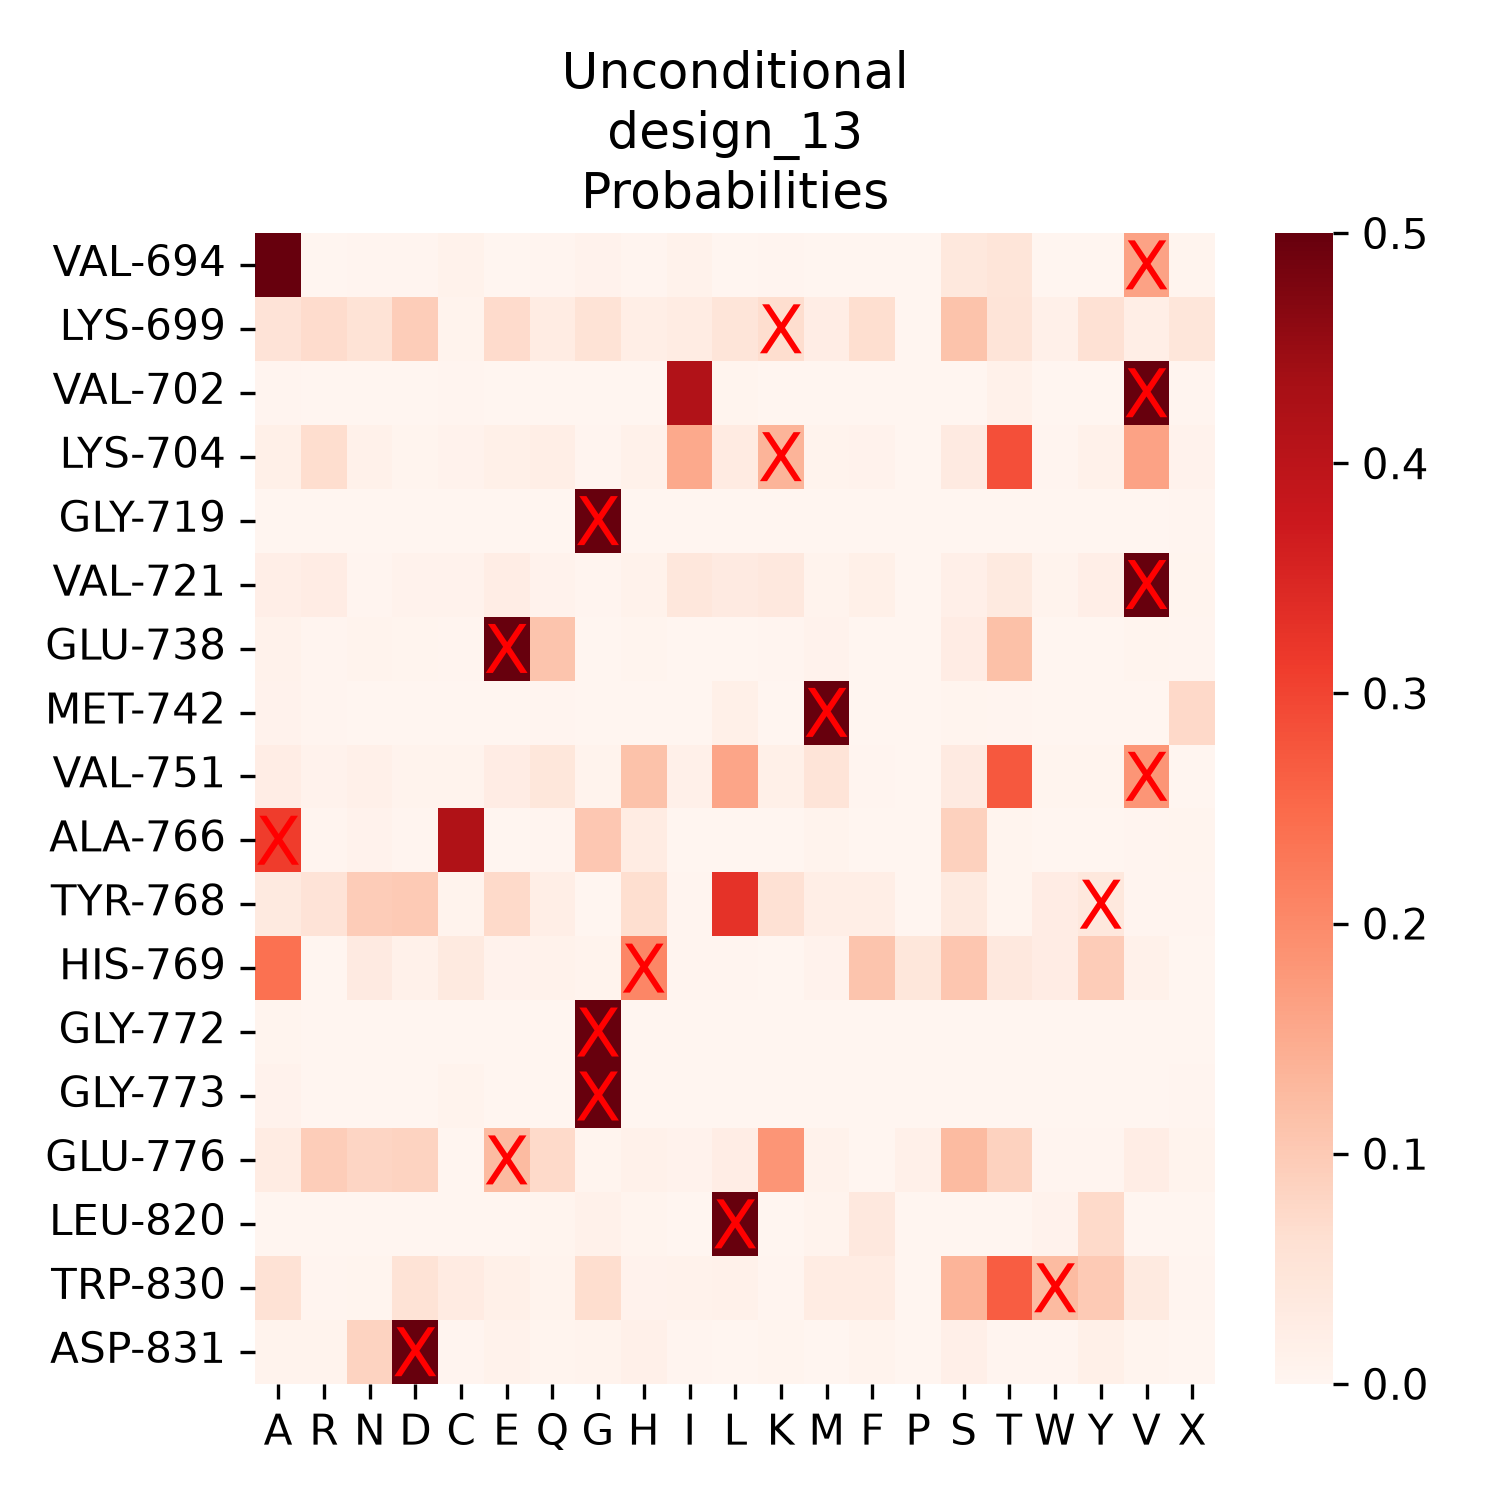

In [ ]:
# Cell 11 -- run LASErMPNN proofreading on the best design

import shutil
from IPython.display import Image, display

if PROOF_DIR.exists():
    shutil.rmtree(PROOF_DIR)
PROOF_DIR.mkdir()

# Proofreading runs on the best design PDB
cmd_proof = (
    f'cd /content/ && {VENV_PY} -m LASErMPNN.run_proofreading '
    f'{best_pdb.absolute()} {PROOF_DIR}/ '
    f'--n_decoding_orders 10 '
    f'--n_dropouts 5 '
    f'-d cuda:0'
)

print(f'Running proofreading on design_{best_idx}...')
print('This evaluates each binding site residue individually.')
print('Runtime: approximately 6 minutes on T4.\n')

result = subprocess.run(cmd_proof, shell=True, capture_output=True, text=True)

if result.returncode != 0:
    print('STDERR:', result.stderr[-3000:])
else:
    print('Proofreading complete.')
    print(result.stdout[:500] if result.stdout else '')

# Display generated plots
png_files = sorted(PROOF_DIR.glob('*.png'))
print(f'\nProofreading outputs: {len(png_files)} plot(s)')

for png in png_files:
    if 'conditional_probs_mean_plus_stddev' not in png.stem:
        print(f'\n{png.name}')
        display(Image(filename=str(png)))

## Cell 12: Interpret Proofreading Results

The proofreading output includes a CSV file with per-residue substitution probabilities. We parse it to find the top candidates for single amino acid improvements -- positions where a different amino acid would significantly increase the model's confidence.

unconditional_probs.png


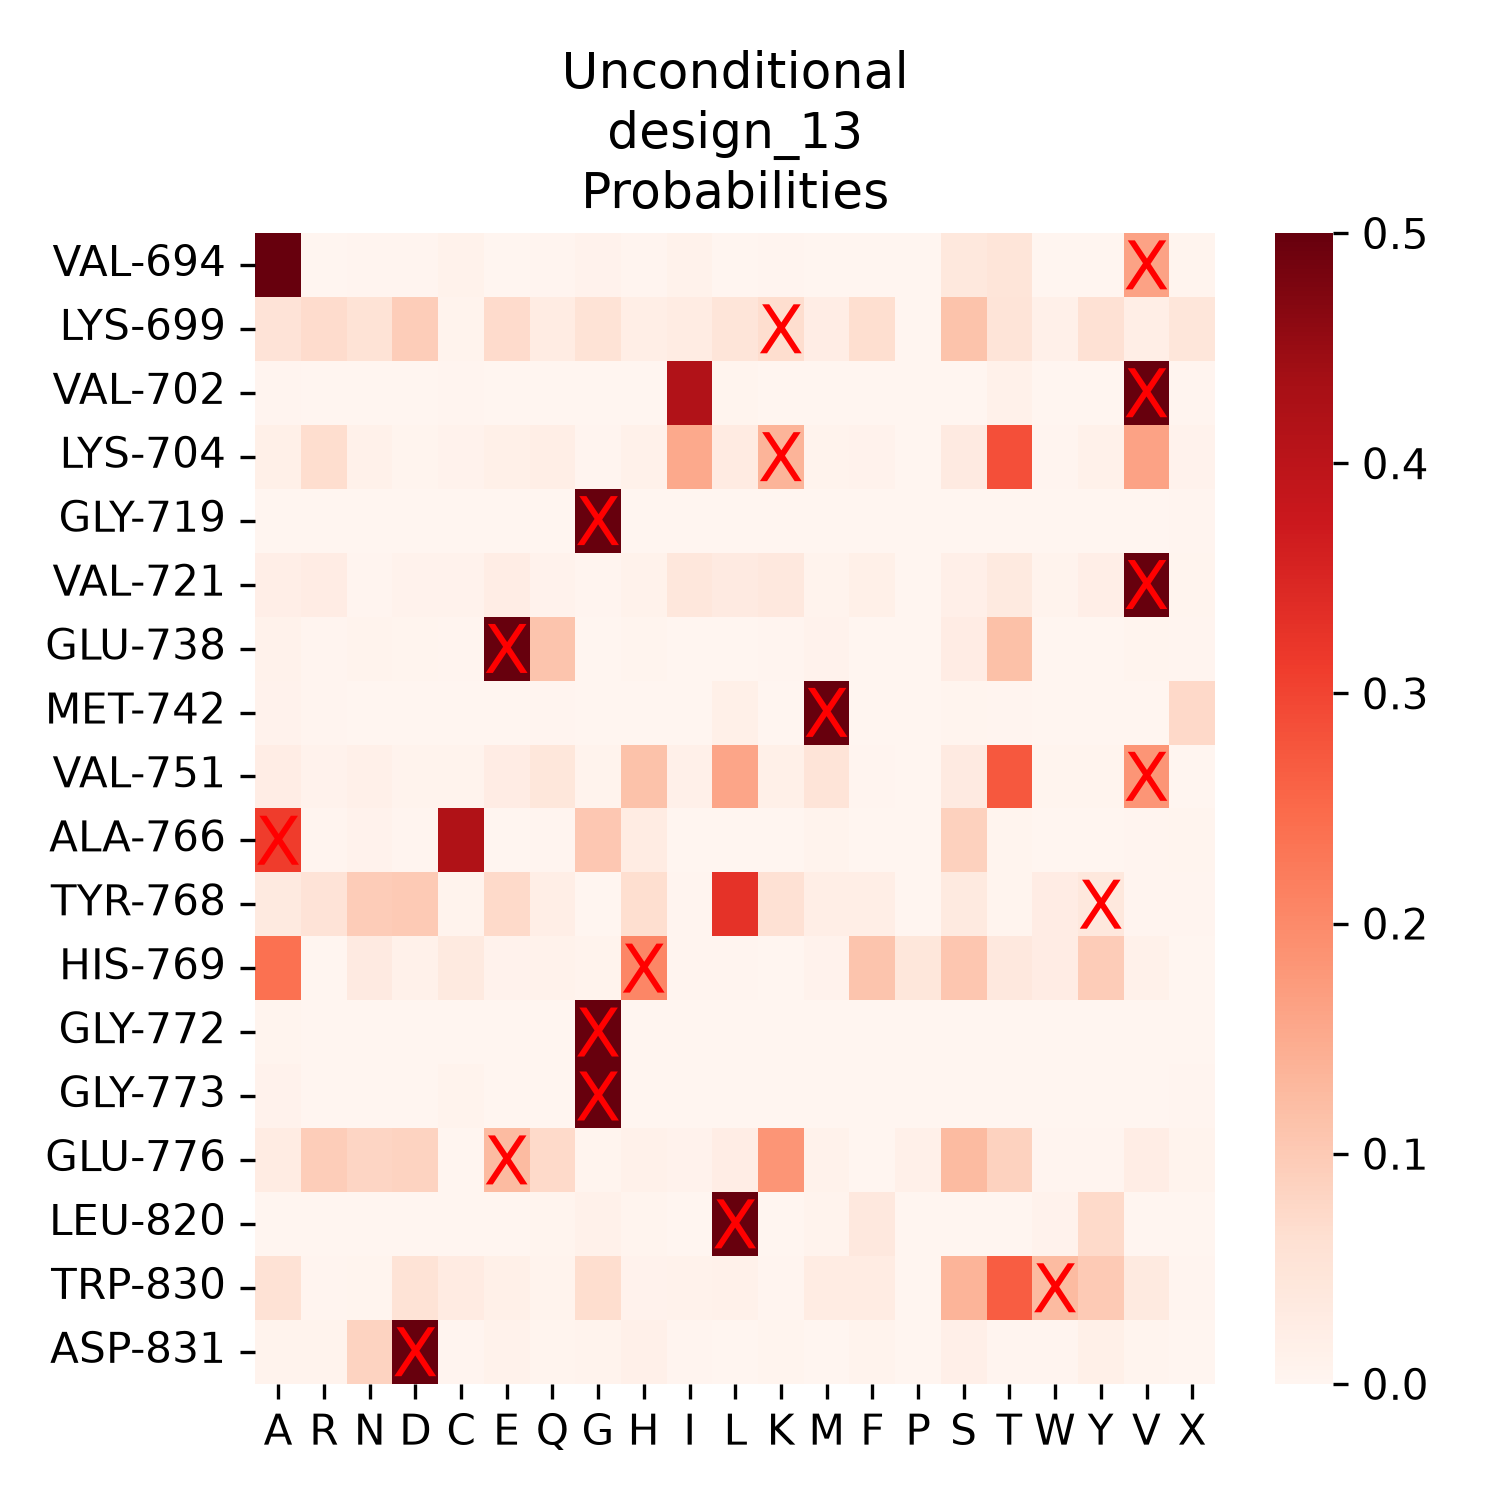

conditional_probs.png


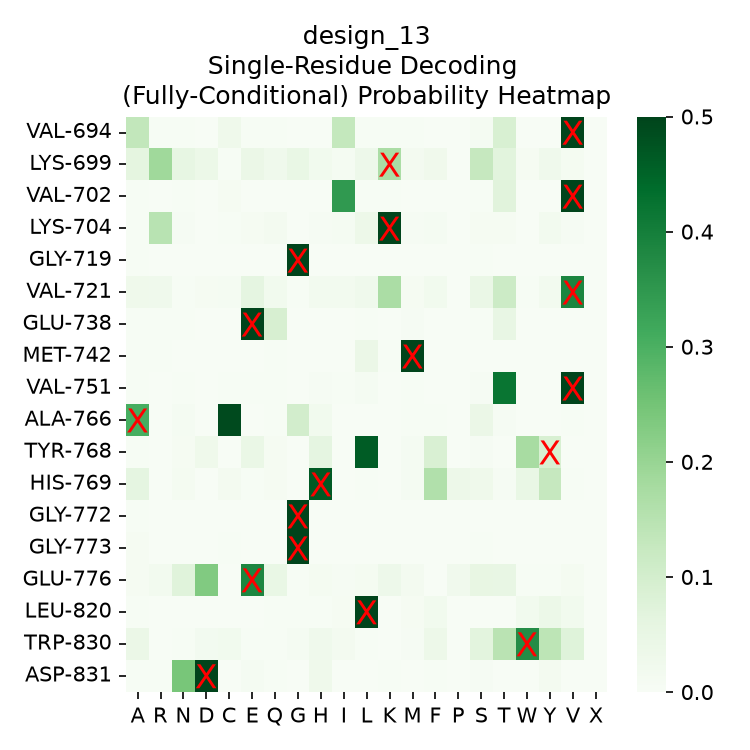


Proofreading tensor file: unconditional_probs.pt
Type: <class 'numpy.ndarray'>
Shape: (18, 21)
This is the per-residue per-amino-acid probability matrix.
Rows = binding site residues, Cols = 20 amino acids + X


In [ ]:
# Cell 12 -- load proofreading .pt output and display substitution probabilities

import torch
from IPython.display import Image, display

# Display the probability plot directly
png_files = list(PROOF_DIR.glob('*.png'))
for png in png_files:
    if 'conditional_probs_mean_plus_stddev' not in png.stem:
        print(f'{png.name}')
        display(Image(filename=str(png), width=900))

# Load the .pt tensor file for detailed analysis
pt_files = list(PROOF_DIR.glob('*.pt'))
if pt_files:
    #data = torch.load(pt_files[0], map_location='cpu')
    data = torch.load(pt_files[0], map_location='cpu', weights_only=False)
    print(f'\nProofreading tensor file: {pt_files[0].name}')
    print(f'Type: {type(data)}')
    if isinstance(data, dict):
        print(f'Keys: {list(data.keys())}')
        for k, v in data.items():
            if hasattr(v, 'shape'):
                print(f'  {k}: shape {v.shape}')
            else:
                print(f'  {k}: {v}')
    elif hasattr(data, 'shape'):
        print(f'Shape: {data.shape}')
        print('This is the per-residue per-amino-acid probability matrix.')
        print(f'Rows = binding site residues, Cols = 20 amino acids + X')

## Cell 13: Summary

A summary of what we demonstrated and how it connects to the broader series.

In [ ]:
# Cell 13 -- summary

print('=' * 65)
print('SUMMARY: LASERMPNN DESIGN -- EGFR + ERLOTINIB')
print('=' * 65)
print(f'Input structure:     {PDB_ID} (EGFR kinase domain + erlotinib co-crystal)')
print(f'Ligand:              ERL (erlotinib, EGFR inhibitor used in Video 10)')
print(f'Model:               LASErMPNN (Fry, Slaw & Polizzi, Nature 2026)')
print(f'Designs generated:   {NUM_DESIGNS}')
print(f'Sequence temp:       {SEQ_TEMP}')
print()
print(f'Best design:         design_{best_idx}')
print(f'Best score:          {best_score:.4f}')
print(f'Mutations vs native: {int(df.iloc[0]["n_mutations"])} positions changed')
seq_id = (1 - df.iloc[0]['n_mutations'] / len(native_seq)) * 100
print(f'Sequence identity:   {seq_id:.1f}% identical to native EGFR')
print()
print('What this demonstrates:')
print('  Video 10 asked: how does erlotinib dock into the EGFR binding pocket?')
print('  This notebook asks: can we design a new protein from scratch that binds erlotinib?')
print()
print('  LASErMPNN takes the crystal pose of erlotinib and designs sequences')
print('  optimized to wrap around it. The proofreading step then identifies')
print('  single-residue improvements -- the same approach used in the Nature')
print('  paper to achieve picomolar affinity for the EPIC protein.')
print()
print('Next steps in a real drug discovery program:')
print('  1. Run the full NISE loop (35 iterations with a structure predictor)')
print('  2. Filter designs by self-consistency (predicted structure matches input)')
print('  3. Rank by buried polar unsatisfied atoms')
print('  4. Order synthetic DNA for the top 4-5 designs')
print('  5. Express in E. coli and measure binding affinity experimentally')
print()
print(f'Outputs saved to: {OUTPUT_DIR}')

SUMMARY: LASERMPNN DESIGN -- EGFR + ERLOTINIB
Input structure:     1M17 (EGFR kinase domain + erlotinib co-crystal)
Ligand:              ERL (erlotinib, EGFR inhibitor used in Video 10)
Model:               LASErMPNN (Fry, Slaw & Polizzi, Nature 2026)
Designs generated:   20
Sequence temp:       0.1

Best design:         design_13
Best score:          -0.6930
Mutations vs native: 29 positions changed
Sequence identity:   90.7% identical to native EGFR

What this demonstrates:
  Video 10 asked: how does erlotinib dock into the EGFR binding pocket?
  This notebook asks: can we design a new protein from scratch that binds erlotinib?

  LASErMPNN takes the crystal pose of erlotinib and designs sequences
  optimized to wrap around it. The proofreading step then identifies
  single-residue improvements -- the same approach used in the Nature
  paper to achieve picomolar affinity for the EPIC protein.

Next steps in a real drug discovery program:
  1. Run the full NISE loop (35 iterations wit